# E19 - the reranker score on a real report and 14 real notes

**Author**: Konrad Jelen (kj)<br>
**Date**: 2026-10-12<br>
**Pipeline stage**: experiment - registered batch `E19`, notebook A, hypothesis `E19-H95`<br>
**Execution model**: session model (one executor agent for the notebook, one independent verifier)

**Purpose** - measure whether the highest reranker score of a report statement over the sentences of one note (`r_i = max_j R[j, i]`) raises the mean AUC over 13 notes by at least 0.03 against the nearest ground cost, with a gain in at least 10 of the 13 notes, on a real report of 883 statements and notes of 22 to 56 statements. The reranker contrast, the Otsu split of `r_i`, the section reading, the hard-negative AUC and the note without a target section are reported without a bar.

**Terms used below**

- **baseline** - `b_i = min_j c_ij`, the nearest ground cost of report statement `i` over the note statements `j`, with `c = cost_matrix(E_report, E_note)`; lower means more relevant; the relevance score is `-b_i`
- **reranker score** - `r_i = max_j R[j, i]` with `R = reranker.score_grid(note statements, report statements)` of `load_reranker()` with its defaults; higher means more relevant
- **AUC** - the probability that a random positive statement has a higher relevance score than a random negative one, ties count one half
- **positive / neutral / negative** - for a note, the report statements under a target heading / under a neutral heading of the fixture or a related heading of the note, which are left out of every metric / all other statements
- **hard negatives** - the negatives whose chapter (first path element) equals the chapter of the note's first target
- **unit** - a heading of `sections.json` with role chapter, numbered or subheading; the section reading ranks units by the mean score of their statements
- **note without a target** - the one note the report has no section for; it is read without a bar and is in no mean

Nothing under `src/`, `tests/`, `docs/` or the fixture is edited. Every bar is the registered one and is applied as written.

## Cells copied from the template

The templates are `notebooks/experiments/E18-kj-contrast-replication.ipynb` and `notebooks/experiments/E18-kj-reranker-relevance.ipynb`. Copied without a change of logic: the environment cell, the imports (with `load_reranker`), the reading cell (one `DocDistance()`, default reader, `embed_statements`, the `section` field of the `flows` of `semantic_distance_with_details`, report first), `auc` (Mann-Whitney, ties one half), the bootstrap (10000 resamples, seed 0, reported), `otsu_threshold`, `balanced_accuracy`, the reranker grid loop (extended by the stored-grid reuse of the registered text) and the metrics cell layout. New in this notebook: the labels from the path rule of `labels.json`, the hard negatives by chapter, the section reading by units with top 3, the gate, the decision and the reading of the note without a target.

## Environment

No GPU is used. The path under test is the shipped OpenVINO INT8 CPU path. Models resolve offline from the local cache; `DOCDISTANCE_HOME` is pinned to the repository root.

In [1]:
import os
import warnings

os.environ["CUDA_VISIBLE_DEVICES"] = ""            # no GPU: the shipped OpenVINO INT8 CPU path is the path under test
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["HF_HUB_OFFLINE"] = "1"                 # models resolve from the local cache through docdistance.json
os.environ["CI"] = "true"                          # disables OpenVINO telemetry
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["DOCDISTANCE_HOME"] = "/home/lab/workspace/learning/projects/docdistance"   # docdistance.json lives at the repo root

warnings.filterwarnings("ignore")
print("environment set: CPU only, models offline, DOCDISTANCE_HOME pinned")

environment set: CPU only, models offline, DOCDISTANCE_HOME pinned


## Imports

The shipped `docdistance` core is imported and never edited.

In [2]:
# Standard library
import contextlib                      # silence the model-load stderr output
import hashlib                         # sha256 of the fixture files
import io                              # sink for the redirected stderr
import json                            # labels, registration and metrics JSON
import platform                        # python version
import re                              # heading numbers in section paths
import time                            # wall time and the write stamp
from datetime import datetime, timezone
from pathlib import Path               # fixture paths

# Scientific
import numpy as np                     # arrays
import ot                              # POT version line; the solves run inside the shipped functions
from scipy.stats import rankdata       # average ranks for the Mann-Whitney AUC

# Visualisation
import matplotlib.pyplot as plt        # inline figures, object-oriented API

# Console
from rich.console import Console
from rich.markup import escape         # lists and file names are printed literally
from rich.table import Table

# The shipped package under test - imported, never edited
import docdistance
from docdistance.distance import cost_matrix                      # ground cost sqrt(2 - 2cos)
from docdistance.encoders import load_reranker                    # bge-reranker-v2-m3, OpenVINO INT8
from docdistance.pipeline import DIFF_CHANGED_COST, DocDistance   # shipped reader, segmenter, encoder; fixed cutoff

%matplotlib inline
console = Console(width=200, highlight=False)
T_START = time.time()
print(f"docdistance {docdistance.__version__} | POT {ot.__version__} | numpy {np.__version__} | python {platform.python_version()}")

docdistance 1.1.32 | POT 0.9.6.post1 | numpy 2.4.6 | python 3.14.8


## Reproducibility

Segmentation, the INT8 encode, the cost matrix and the reranker are deterministic. One seed drives the bootstrap.

In [3]:
SEED = 0
print(f"SEED = {SEED}")

SEED = 0


## Configuration

Every path, constant and bar of the notebook is set in the next cell. The fixture hash check runs here: every file of the registration must equal its stored sha256.

In [4]:
ROOT = Path(os.environ["DOCDISTANCE_HOME"])
FIXTURE = ROOT / "data/processed/relevance-fixture-eu"
REGISTRATION = ROOT / "reports/E19-relevance/E19-relevance-registration.json"
METRICS_FILE = ROOT / "reports/E19-real-document-reranker-metrics.json"
GRIDS_FILE = ROOT / "data/interim/E19/reranker-grids.npz"

BATCH_GATE_AUC = 0.95                  # baseline mean AUC over the 13 notes at or above this kills E19-H95 at the gate
BAR_GAIN = 0.03                        # E19-H95: mean AUC difference to the baseline
BAR_COUNT = 10                         # E19-H95: notes (of 13) with a difference above 0
MIN_TARGET_STATEMENTS = 5              # fixture check: statements under the targets of a note, in total
MIN_UNIT_STATEMENTS = 5                # section reading: units below this are left out
TOP_N_UNITS = 3                        # section reading: top-3 hit
UNIT_ROLES = ("chapter", "numbered", "subheading")
N_BOOT = 10000                         # bootstrap resamples of the mean difference (reported, no bar)

LABELS = json.loads((FIXTURE / "labels.json").read_text(encoding="utf-8"))
SECTIONS = json.loads((FIXTURE / "sections.json").read_text(encoding="utf-8"))["sections"]
REG = json.loads(REGISTRATION.read_text(encoding="utf-8"))
NEUTRAL = LABELS["neutral_sections"]
NOTE_SPEC = LABELS["notes"]
NO_TARGET = list(LABELS["no_target_notes"])
assert len(NO_TARGET) == 1
NOTE_SPEC = {**NOTE_SPEC, **{n: {**v, "target_sections": [], "related_sections": []} for n, v in LABELS["no_target_notes"].items() if n not in NOTE_SPEC}}
NOTE_IDS = sorted(NOTE_SPEC)
TARGET_IDS = [n for n in NOTE_IDS if n not in NO_TARGET]
NT = NO_TARGET[0]
assert len(NOTE_IDS) == 14 and len(TARGET_IDS) == 13

fixture_sha = {rel: hashlib.sha256((ROOT / rel).read_bytes()).hexdigest() for rel in REG["fixture_sha256"]}
HASH_EQUAL = bool(fixture_sha == REG["fixture_sha256"])
assert HASH_EQUAL, "fixture differs from the registration"

table = Table(title="Configuration", show_lines=False)
table.add_column("item"); table.add_column("value")
for key, value in [
    ("fixture", FIXTURE.relative_to(ROOT)), ("notes with targets / without", f"{len(TARGET_IDS)} / {len(NO_TARGET)}"),
    ("neutral headings", NEUTRAL), ("DIFF_CHANGED_COST (fixed cutoff)", DIFF_CHANGED_COST),
    ("batch gate", f"baseline mean AUC over the 13 notes >= {BATCH_GATE_AUC} kills E19-H95"),
    ("bar E19-H95", f"mean diff >= {BAR_GAIN} and diff > 0 in >= {BAR_COUNT} of 13"),
    ("section reading", f"units {UNIT_ROLES} with >= {MIN_UNIT_STATEMENTS} statements, top {TOP_N_UNITS}"),
    ("bootstrap", f"{N_BOOT} resamples, seed {SEED} (reported, no bar)"), ("grids file", GRIDS_FILE.relative_to(ROOT)),
    ("fixture sha256", f"all {len(fixture_sha)} files equal the registration"),
]:
    table.add_row(str(key), escape(str(value)))
console.print(table)

                                                   Configuration                                                    
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ item                             ┃ value                                                                         ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ fixture                          │ data/processed/relevance-fixture-eu                                           │
│ notes with targets / without     │ 13 / 1                                                                        │
│ neutral headings                 │ ['Introduction', '1. Key drivers of the EU’s digital transformation in 2024'] │
│ DIFF_CHANGED_COST (fixed cutoff) │ 0.3252691193458119                                                            │
│ batch gate                       │ baseline mean AUC over the 13 notes >= 0.95 kills E19-H95                     │
│ bar E19-H95                      │ mean diff >= 0.03 and diff > 0 in >= 10 of 13                                 │
│ section reading                  │ units ('chapter', 'numbered', 'subheading') with >= 5 statements, top 3       │
│ bootstrap                        │ 10000 resamples, seed 0 (reported, no bar)                                    │
│ grids file                       │ data/interim/E19/reranker-grids.npz                                           │
│ fixture sha256                   │ all 18 files equal the registration                                           │
└──────────────────────────────────┴───────────────────────────────────────────────────────────────────────────────┘

## Reading

One `DocDistance()` with the shipped defaults. The report is the first document of `semantic_distance_with_details`, so the `section` field of its `flows` gives the section path of every report statement. The 14 notes are encoded by `embed_statements`.

In [5]:
with contextlib.redirect_stderr(io.StringIO()):
    dd = DocDistance()
    report_path = FIXTURE / LABELS["report"]
    R_TEXTS, E_R = dd.embed_statements(report_path)
    _, DETAIL = dd.semantic_distance_with_details(report_path, FIXTURE / NOTE_SPEC[NOTE_IDS[0]]["file"])
    NOTE_TEXTS, E_NOTE = {}, {}
    for nid in NOTE_IDS:
        NOTE_TEXTS[nid], E_NOTE[nid] = dd.embed_statements(FIXTURE / NOTE_SPEC[nid]["file"])

FLOWS = DETAIL["flows"]
assert [f["text"] for f in FLOWS] == R_TEXTS, "flow texts differ from the report statements"
SECTION_PATH = [f["section"] for f in FLOWS]
assert all(SECTION_PATH), "a report statement has no section"
PATH_ELEMENTS = [p.split(" > ") for p in SECTION_PATH]
N_REPORT = len(R_TEXTS)
assert N_REPORT == 883, f"the report holds {N_REPORT} statements, not 883"
console.print(f"report {N_REPORT} statements in {len(set(SECTION_PATH))} distinct section paths")
console.print("notes " + ", ".join(f"{n[:6]}: {len(NOTE_TEXTS[n])}" for n in NOTE_IDS))
assert all(22 <= len(NOTE_TEXTS[n]) <= 56 for n in NOTE_IDS), "a note is outside 22 to 56 statements"

report 883 statements in 113 distinct section paths

notes 739206: 51, 739350: 49, 747926: 32, 751386: 23, 754642: 29, 759583: 26, 759620: 29, 760355: 52, 760391: 22, 760392: 32, 760421: 25, 772906: 26, 779193: 56, 779252: 51

## Labels

The path of a statement is split at ` > `. A statement is neutral for every note when one element of its path equals a heading in `neutral_sections`; neutral for one note when an element equals one of that note's `related_sections`; positive when an element equals one of the note's `target_sections`; negative otherwise. Neutral statements are left out of every metric. The distinct path elements are printed once so the reader sees that the heading texts of the label file equal the path elements.

In [6]:
DISTINCT_ELEMENTS = list(dict.fromkeys(e for els in PATH_ELEMENTS for e in els))
console.print(f"{len(DISTINCT_ELEMENTS)} distinct path elements:")
console.print(escape(" | ".join(DISTINCT_ELEMENTS)))
all_headings = set(NEUTRAL) | {h for s in NOTE_SPEC.values() for h in s["target_sections"] + s["related_sections"]}
missing = sorted(h for h in all_headings if h not in set(DISTINCT_ELEMENTS))
assert not missing, f"headings of the label file that are no path element: {missing}"

has = lambda els, names: any(e in names for e in els)
IS_NEUTRAL_GLOBAL = np.array([has(els, NEUTRAL) for els in PATH_ELEMENTS])
LAB = {}
for nid in NOTE_IDS:
    spec = NOTE_SPEC[nid]
    neutral = IS_NEUTRAL_GLOBAL | np.array([has(els, spec["related_sections"]) for els in PATH_ELEMENTS])
    pos = np.array([has(els, spec["target_sections"]) for els in PATH_ELEMENTS]) & ~neutral
    if nid not in NO_TARGET:
        total_target = int(np.array([has(els, spec["target_sections"]) for els in PATH_ELEMENTS]).sum())
        assert total_target >= MIN_TARGET_STATEMENTS, f"{nid}: targets hold {total_target} statements"
        assert not (pos & neutral).any()
        chapters = {els[0] for els, p in zip(PATH_ELEMENTS, pos) if p}
        assert len(chapters) >= 1
        chapter = PATH_ELEMENTS[int(np.flatnonzero(np.array([has(els, spec["target_sections"][:1]) for els in PATH_ELEMENTS]))[0])][0]
        hard = ~pos & ~neutral & np.array([els[0] == chapter for els in PATH_ELEMENTS])
    else:
        assert not pos.any()
        hard = None
    LAB[nid] = {"pos": pos, "neutral": neutral, "neg": ~pos & ~neutral, "hard": hard, "targets": spec["target_sections"],
                "neutral_headings": NEUTRAL + spec["related_sections"]}
LABEL_ASSERTION_PASSED = True

table = Table(title="Label counts per note")
for col in ("note", "statements", "positives", "neutral", "negatives", "hard negatives", "targets"):
    table.add_column(col)
for nid, lab in LAB.items():
    table.add_row(nid, str(len(NOTE_TEXTS[nid])), str(lab["pos"].sum()), str(lab["neutral"].sum()), str(lab["neg"].sum()),
                  "-" if lab["hard"] is None else str(lab["hard"].sum()), escape("; ".join(lab["targets"]) or "none (no target section)"))
console.print(table)
console.print("label-count assertion: every note with a target holds at least 5 statements under its targets -> PASSED")

88 distinct path elements:

Introduction | 1. Key drivers of the EU’s digital transformation in 2024 | 1.1. A new geopolitical paradigm | 1.2. Fostering competitiveness in a complex economic context | 1.3. Entering a new age 
shaped by generative AI | 1.4. Keeping people and societies on board in an increasingly hybrid context | 2. A competitive, sovereign and resilient EU based on technological leadership | 2.1. Building 
digital technological leadership for future competitiveness | 2.1.1. Investing in research and innovation | Technological leadership - Recommended policies, measures and actions (49): | Mobilising 
investments | Completing the Digital Single market | Fostering cooperation between Member States | 2.1.2. A functioning Digital Single Market as a public good for EU’s productivity | 2.1.3. Developing
and deploying sovereign and resilient collaborative connectivity and computing infrastructure | 2.1.3.1 Gigabit connectivity infrastructure | Connectivity - Recommended policies, measures and actions:
| 2.1.3.2 Semiconductors | Semiconductors - Recommended policies, measures and actions: | Mobilising investments and fostering cooperation between MSs | 2.1.3.3 Edge nodes | Edge Nodes - Recommended 
policies, measures and actions: | 2.1.3.4 Quantum computing | 'Quantum technologies' start-ups (2023) | Quantum - Recommended policies, measures and actions: | Fostering cooperation between MSs: | 
2.2. Supporting EU-wide digital ecosystems and scaling up innovative enterprises | 2.2.1. Promoting the digital transformation of EU enterprises | 2.2.1.1 Take up of advanced digital technologies | 
Take up of cloud services | Take up of artificial intelligence | Take up of big data/use of data analytics | Take up of Cloud-AI-Big Data - Recommended policies, measures and actions: | Disseminating 
digital technologies | Completing the Digital Single market and fostering cooperation between Member States: | 2.2.1.2 Fostering the digitalisation of SMEs | Digitalisation of SMEs - Recommended 
policies, measures and actions: | Mobilising investments: | Disseminating digital technologies: | 2.2.2. Scaling up innovative enterprise | Unicorns - Recommended policies, measures and actions: | 
2.3. Strengthening cybersecurity | Objective Cybersecurity - Recommended policies, measures and actions: | Completing the Digital Single Market | 3. Protecting and empowering EU people and society | 
3.1. Empower people and bring the digital transformation closer to their needs | 3.1.1. Equip people with digital skills | A digitally skilled population: at least basic digital skills | Basic skills 
- Recommended policies, measures and actions: | A highly skilled digital workforce: ICT specialists and advanced digital skills | ICT specialists - Recommended policies, measures and actions: | 3.1.2.
Trusted solutions for digital interaction: the EU Digital Identity and the digital euro | EU Digital Identity - Recommended policies, measures and actions: | 3.1.3. Efficient digital public services 
user-friendly and accessible to all | e-Government services - Recommended policies, measures and actions: | Mobilising investments and completing the Digital Single market: | 3.1.4. Leverage on 
digital technologies for health | e-health - Recommended policies, measures and actions: | Completing the Digital Single market: | 3.2. Protect people and a build safe and human centric digital 
environment and technologies | 3.2.1. Build safe digital environments and safeguard fundamental rights online | Objective safeguarding rights - Recommended policies, measures and actions: | 3.2.2. 
Protect and empower children (including via age verification) | Objective: protecting kids - Recommended policies, measures and actions: | Cooperation | 3.2.3. Promote responsible and human-centric AI
systems | Objective Human centred - Recommended policies, measures and actions: | 3.3. Promote and preserve our democracy | 3.3.1. Address disinformation and preserve election integrity | Objective 
protecting democrac

                                                                                         Label counts per note                                                                                          
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ note                                      ┃ statements ┃ positives ┃ neutral ┃ negatives ┃ hard negatives ┃ targets                                                                                  ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 739206-european-year-of-skills            │ 51         │ 67        │ 68      │ 748       │ 210            │ 3.1.1. Equip people with digital skills                                                  │
│ 739350-online-age-verification            │ 49         │ 25        │ 122     │ 736       │ 198            │ 3.2.2. Protect and empower children (including via age verification)                     │
│ 747926-ai-act-parliament-position         │ 32         │ 16        │ 85      │ 782       │ 261            │ 3.2.3. Promote responsible and human-centric AI systems                                  │
│ 751386-eu-chips-act                       │ 23         │ 38        │ 68      │ 777       │ 329            │ 2.1.3.2 Semiconductors                                                                   │
│ 754642-european-health-data-space         │ 29         │ 26        │ 68      │ 789       │ 251            │ 3.1.4. Leverage on digital technologies for health                                       │
│ 759583-strategic-technologies-platform    │ 26         │ 54        │ 68      │ 761       │ 343            │ 2.1.1. Investing in research and innovation; 5.3. Synergising funding for digitalisation │
│ 759620-european-media-freedom-act         │ 29         │ 13        │ 91      │ 779       │ 241            │ 3.3.2. Access to media and media pluralism                                               │
│ 760355-foreign-interference-preparedness  │ 52         │ 23        │ 116     │ 744       │ 241            │ 3.3.1. Address disinformation and preserve election integrity                            │
│ 760391-gdpr-cross-border-procedural-rules │ 22         │ 0         │ 68      │ 815       │ -              │ none (no target section)                                                                 │
│ 760392-ai-investment-indicators           │ 32         │ 17        │ 137     │ 729       │ 297            │ Take up of artificial intelligence                                                       │
│ 760421-gigabit-infrastructure-act         │ 25         │ 57        │ 68      │ 758       │ 310            │ 2.1.3.1 Gigabit connectivity infrastructure                                              │
│ 772906-ai-act-implementation-timeline     │ 26         │ 16        │ 85      │ 782       │ 261            │ 3.2.3. Promote responsible and human-centric AI systems                                  │
│ 779193-simplifying-digital-laws           │ 56         │ 19        │ 94      │ 770       │ 66             │ 5.2. Striving for an effective, efficient and red-tape free implementation of the        │
│                                           │            │           │         │           │                │ digital regulatory environment                                                           │
│ 779252-cybersecurity-act-review           │ 51         │ 35        │ 68      │ 780       │ 332            │ 2.3. Strengthening cybersecurity                                                         │
└───────────────────────────────────────────┴────────────┴───────────┴─────────┴───────────┴────────────────┴────────────────────────────────────────────────────────────────────────

label-count assertion: every note with a target holds at least 5 statements under its targets -> PASSED

## Units for the section reading

A unit is a heading of `sections.json` with role chapter, numbered or subheading. A path element is matched to a heading by its number and title (the path writes `2.1.3.1 Title`, `1. Title` or `Title`). A statement belongs to the deepest element of its path that is a unit. A unit is identified by its path prefix, so two headings with one title stay apart.

In [7]:
NUM = re.compile(r"^(\d+(?:\.\d+)*)\.?\s+(.*)$")


def heading_key(element):
    "(number, title) of a path element; number is None for a heading without one"
    m = NUM.match(element)
    return (m.group(1), m.group(2).strip()) if m else (None, element.strip())


UNIT_KEYS = {(s["number"], s["title"].strip()) for s in SECTIONS if s["role"] in UNIT_ROLES}
OTHER_KEYS = {(s["number"], s["title"].strip()) for s in SECTIONS if s["role"] not in UNIT_ROLES}
assert not (UNIT_KEYS & OTHER_KEYS), f"a unit heading shares number and title with another heading: {UNIT_KEYS & OTHER_KEYS}"
UNIT_OF = []                                  # per report statement: the path prefix up to its deepest unit
for els in PATH_ELEMENTS:
    idx = [k for k, e in enumerate(els) if heading_key(e) in UNIT_KEYS]
    assert idx, f"no unit in the path {els}"
    UNIT_OF.append(tuple(els[: idx[-1] + 1]))
UNITS = list(dict.fromkeys(UNIT_OF))
UNIT_INDEX = {u: np.array([i for i, x in enumerate(UNIT_OF) if x == u]) for u in UNITS}
found = {heading_key(u[-1]) for u in UNITS}
console.print(f"{len(UNIT_KEYS)} unit headings in sections.json; {len(UNITS)} distinct units hold statements; "
              f"{sum(len(v) < MIN_UNIT_STATEMENTS for v in UNIT_INDEX.values())} hold fewer than {MIN_UNIT_STATEMENTS} statements")


def units_for(nid):
    "Units with at least 5 statements that are not neutral for the note (a neutral heading is the unit or one of its ancestors)"
    heads = LAB[nid]["neutral_headings"]
    return [u for u in UNITS if len(UNIT_INDEX[u]) >= MIN_UNIT_STATEMENTS and not any(e in heads for e in u)]


def section_reading(score, nid):
    "Units ranked from most to least relevant by mean score; rank of the best target unit and top-3 hit (None for a note without a target)"
    units = units_for(nid)
    means = np.array([float(score[UNIT_INDEX[u]].mean()) for u in units])
    ranked = [units[i] for i in np.argsort(-means, kind="stable")]
    targets = LAB[nid]["targets"]
    if not targets:
        return {"ranked": [" > ".join(u) for u in ranked], "best_target_rank": None, "top3_hit": None, "n_units": len(units)}
    ranks = [r + 1 for r, u in enumerate(ranked) if any(e in targets for e in u)]
    assert ranks, f"{nid}: no target unit is among the {len(units)} units"
    return {"ranked": [" > ".join(u) for u in ranked], "best_target_rank": min(ranks), "top3_hit": bool(min(ranks) <= TOP_N_UNITS), "n_units": len(units)}

49 unit headings in sections.json; 49 distinct units hold statements; 8 hold fewer than 5 statements

## Baseline and metric functions

The baseline `b_i` is the row minimum of the cost matrix of the report against the note. The AUC is the Mann-Whitney statistic from average ranks, so ties count one half. `otsu_threshold` and `balanced_accuracy` are copied from the template.

In [8]:
BASE_COST = {nid: cost_matrix(E_R, E_NOTE[nid]).astype(np.float64).min(axis=1) for nid in NOTE_IDS}


def auc(score, pos, neg):
    "Mann-Whitney AUC of a relevance score for positives against negatives; ties count one half"
    ranks = rankdata(np.concatenate([score[pos], score[neg]]))
    n_pos, n_neg = int(pos.sum()), int(neg.sum())
    return float((ranks[:n_pos].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def otsu_threshold(values):
    "Exact Otsu split of a sample: the midpoint between neighbouring distinct sorted values with the largest between-class variance"
    v = np.sort(values)
    distinct = np.unique(v)
    best_var, best_t = -1.0, None
    for t in (distinct[:-1] + distinct[1:]) / 2:
        lo, hi = v[v <= t], v[v > t]
        var = (len(lo) / len(v)) * (len(hi) / len(v)) * (lo.mean() - hi.mean()) ** 2
        if var > best_var:                       # strict: an exact tie keeps the lower threshold
            best_var, best_t = var, float(t)
    return best_t


def balanced_accuracy(match, pos, neg):
    "Mean of the recall on positives (match) and the recall on negatives (no match)"
    return float((match[pos].mean() + (~match[neg]).mean()) / 2)


fmt = lambda v: "-" if v is None else f"{v:.4f}"
cell = lambda d: f"[red]{d:+.4f}[/red]" if d < 0 else f"{d:+.4f}"
print(f"baseline nearest costs computed for {len(NOTE_IDS)} notes")

baseline nearest costs computed for 14 notes


## Reranker grids

`load_reranker()` with its defaults; `R = reranker.score_grid(note statements, report statements)`; `r_i = max_j R[j, i]`. The notes are computed one at a time. After every note the file `data/interim/E19/reranker-grids.npz` is rewritten with all grids so far and the seconds of each, and a grid found in the file is reused, so an interrupted run continues. The cell states how many grids were computed in this run and how many were read from the file.

In [9]:
GRIDS_FILE.parent.mkdir(parents=True, exist_ok=True)
STORED = {}
if GRIDS_FILE.exists():
    with np.load(GRIDS_FILE) as z:
        STORED = {k: z[k] for k in z.files}
GRID, GRID_SECONDS, SOURCE = {}, {}, {}
reranker = None
for nid in NOTE_IDS:
    shape = (len(NOTE_TEXTS[nid]), N_REPORT)
    if nid in STORED and f"seconds__{nid}" in STORED and STORED[nid].shape == shape:
        GRID[nid], GRID_SECONDS[nid], SOURCE[nid] = STORED[nid], float(STORED[f"seconds__{nid}"]), "file"
        continue
    if reranker is None:
        with contextlib.redirect_stderr(io.StringIO()):
            reranker = load_reranker()
    t0 = time.perf_counter()
    grid = reranker.score_grid(NOTE_TEXTS[nid], R_TEXTS)
    GRID_SECONDS[nid] = time.perf_counter() - t0
    assert grid.shape == shape and np.isfinite(grid).all() and grid.min() >= 0 and grid.max() <= 1
    GRID[nid], SOURCE[nid] = grid, "computed"
    STORED[nid], STORED[f"seconds__{nid}"] = grid, np.array(GRID_SECONDS[nid])
    np.savez_compressed(GRIDS_FILE, **STORED)
    print(f"{nid}: {shape[0]} x {shape[1]} = {shape[0] * shape[1]} pairs in {GRID_SECONDS[nid]:.1f} s", flush=True)

N_COMPUTED = sum(v == "computed" for v in SOURCE.values())
N_FROM_FILE = sum(v == "file" for v in SOURCE.values())
RERANKER_CLASS = type(reranker).__name__ if reranker is not None else "not loaded in this run (all grids read from the file)"
PAIRS = {nid: GRID[nid].size for nid in NOTE_IDS}
console.print(f"grids computed in this run: {N_COMPUTED}; grids read from {GRIDS_FILE.relative_to(ROOT)}: {N_FROM_FILE}; total pairs {sum(PAIRS.values())}")
RERANK_R = {nid: GRID[nid].max(axis=0).astype(np.float64) for nid in NOTE_IDS}

grids computed in this run: 0; grids read from data/interim/E19/reranker-grids.npz: 14; total pairs 444149

## Scores and area under the curve

Every score is a relevance score, a higher value meaning a more relevant statement.

- `baseline` - `-b_i`
- `reranker` - `r_i`
- `contrast` - `r_i` minus the mean of `r_i` over the other 12 notes with a target; for the note without a target the mean over the 13 notes (reported, no bar)

In [10]:
S = {"baseline": {n: -BASE_COST[n] for n in NOTE_IDS}, "reranker": dict(RERANK_R), "contrast": {}}
for nid in NOTE_IDS:
    S["contrast"][nid] = RERANK_R[nid] - np.mean([RERANK_R[b] for b in TARGET_IDS if b != nid], axis=0)
NAMES = list(S)

AUC = {n: {t: auc(S[n][t], LAB[t]["pos"], LAB[t]["neg"]) for t in TARGET_IDS} for n in NAMES}
AUC_HARD = {n: {t: auc(S[n][t], LAB[t]["pos"], LAB[t]["hard"]) for t in TARGET_IDS} for n in NAMES}
SECTION = {n: {t: section_reading(S[n][t], t) for t in NOTE_IDS} for n in NAMES}

BOOT_IDX = np.random.default_rng(SEED).integers(0, len(TARGET_IDS), size=(N_BOOT, len(TARGET_IDS)))


def summarise(name):
    "Mean AUC, difference to the baseline, count above 0, bootstrap interval, hard-negative AUC and top-3 hits over the 13 notes"
    diff = np.array([AUC[name][t] - AUC["baseline"][t] for t in TARGET_IDS])
    boot = diff[BOOT_IDX].mean(axis=1)
    hard_diff = np.array([AUC_HARD[name][t] - AUC_HARD["baseline"][t] for t in TARGET_IDS])
    return {"mean_auc": float(np.mean([AUC[name][t] for t in TARGET_IDS])), "mean_diff": float(diff.mean()), "n_above_0": int((diff > 0).sum()),
            "boot_lo": float(np.percentile(boot, 2.5)), "boot_hi": float(np.percentile(boot, 97.5)),
            "hard_mean_auc": float(np.mean([AUC_HARD[name][t] for t in TARGET_IDS])), "hard_mean_diff": float(hard_diff.mean()),
            "top3_hits": int(sum(SECTION[name][t]["top3_hit"] for t in TARGET_IDS)),
            "median_best_target_rank": float(np.median([SECTION[name][t]["best_target_rank"] for t in TARGET_IDS]))}


SUMMARY = {n: summarise(n) for n in NAMES}
table = Table(title="Score summary over the 13 notes with a target")
for col in ("score", "mean AUC", "mean diff", "notes > 0", "boot 95% (mean diff)", "hard-neg AUC", "hard-neg diff", "top-3 hits", "median rank of best target unit"):
    table.add_column(col, justify="right" if col != "score" else "left")
for n, s in SUMMARY.items():
    table.add_row(n, fmt(s["mean_auc"]), f"{s['mean_diff']:+.4f}", f"{s['n_above_0']}/13", f"[{s['boot_lo']:+.4f}, {s['boot_hi']:+.4f}]",
                  fmt(s["hard_mean_auc"]), f"{s['hard_mean_diff']:+.4f}", f"{s['top3_hits']}/13", f"{s['median_best_target_rank']:.1f}")
console.print(table)

                                                   Score summary over the 13 notes with a target                                                    
┏━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ score    ┃ mean AUC ┃ mean diff ┃ notes > 0 ┃ boot 95% (mean diff) ┃ hard-neg AUC ┃ hard-neg diff ┃ top-3 hits ┃ median rank of best target unit ┃
┡━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ baseline │   0.6374 │   +0.0000 │      0/13 │   [+0.0000, +0.0000] │       0.6305 │       +0.0000 │       5/13 │                             6.0 │
│ reranker │   0.8321 │   +0.1947 │     13/13 │   [+0.1440, +0.2434] │       0.8187 │       +0.1882 │      12/13 │                             1.0 │
│ contrast │   0.8231 │   +0.1857 │     13/13 │   [+0.1455, +0.2264] │       0.8144 │       +0.1839 │      12/13 │                             1.0 │
└──────────┴──────────┴───────────┴───────────┴──────────────────────┴──────────────┴───────────────┴────────────┴─────────────────────────────────┘

## Gates

The batch gate is read before any bar: a baseline mean AUC of 0.95 or more over the 13 notes kills `E19-H95` at the gate. A hypothesis killed at the gate keeps its readings, labelled as beyond the gate.

In [11]:
BASE_MEAN = SUMMARY["baseline"]["mean_auc"]
H95_KILLED = bool(BASE_MEAN >= BATCH_GATE_AUC)
GATE_READING = f"baseline mean AUC over the 13 notes {BASE_MEAN:.4f} vs {BATCH_GATE_AUC} -> {'KILLED at the gate' if H95_KILLED else 'passed'}"
console.print(f"E19-H95 batch gate: {GATE_READING}")

E19-H95 batch gate: baseline mean AUC over the 13 notes 0.6374 vs 0.95 -> passed

## E19-H95 - the reranker score against the nearest cost

Bar: Confirmed iff the mean over the 13 notes of (reranker AUC - baseline AUC) is at least 0.03 and the difference is above 0 in at least 10 of the 13 notes.

In [12]:
s95 = SUMMARY["reranker"]
CLAUSES = {"mean_diff_ge_0.03": {"value": s95["mean_diff"], "met": bool(s95["mean_diff"] >= BAR_GAIN)},
           "notes_above_0_ge_10": {"value": s95["n_above_0"], "met": bool(s95["n_above_0"] >= BAR_COUNT)}}
BAR_MET = bool(all(c["met"] for c in CLAUSES.values()))
VERDICT = "Killed-at-gate" if H95_KILLED else ("Confirmed" if BAR_MET else "Refuted")

table = Table(title="E19-H95 bar clauses (value -> met)")
for col in ("clause", "value", "met"):
    table.add_column(col)
table.add_row("mean diff >= 0.03", f"{s95['mean_diff']:+.4f} (reranker {s95['mean_auc']:.4f}, baseline {BASE_MEAN:.4f})", str(CLAUSES["mean_diff_ge_0.03"]["met"]))
table.add_row("notes with diff > 0 >= 10 of 13", str(s95["n_above_0"]), str(CLAUSES["notes_above_0_ge_10"]["met"]))
console.print(table)
console.print(f"E19-H95: bar met {BAR_MET}; verdict_by_bar {VERDICT}" + (" (readings beyond the gate)" if H95_KILLED else ""))
console.print(f"bootstrap 95% interval of the mean difference ({N_BOOT} resamples, seed {SEED}, reported): [{s95['boot_lo']:+.4f}, {s95['boot_hi']:+.4f}]")

                          E19-H95 bar clauses (value -> met)                           
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┓
┃ clause                          ┃ value                                      ┃ met  ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━┩
│ mean diff >= 0.03               │ +0.1947 (reranker 0.8321, baseline 0.6374) │ True │
│ notes with diff > 0 >= 10 of 13 │ 13                                         │ True │
└─────────────────────────────────┴────────────────────────────────────────────┴──────┘

E19-H95: bar met True; verdict_by_bar Confirmed

bootstrap 95% interval of the mean difference (10000 resamples, seed 0, reported): [+0.1440, +0.2434]

## Readings without a bar

The Otsu split is taken on `r_i` of every report statement of the pair, neutral statements included; a statement matches iff `r_i` is above the threshold. The fixed cutoff is the shipped `DIFF_CHANGED_COST` on the nearest cost. Balanced accuracy is read on the non-neutral statements.

In [13]:
def ba_row(match, nid):
    lab = LAB[nid]
    return {"ba": balanced_accuracy(match, lab["pos"], lab["neg"]), "n_match": int(match.sum()),
            "tpr": float(match[lab["pos"]].mean()), "tnr": float((~match[lab["neg"]]).mean())}


FIXED, OTSU = {}, {}
for t in TARGET_IDS:
    FIXED[t] = ba_row(BASE_COST[t] <= DIFF_CHANGED_COST, t)
    thr = otsu_threshold(RERANK_R[t])
    OTSU[t] = {**ba_row(RERANK_R[t] > thr, t), "threshold": thr}
FIXED_MEAN = float(np.mean([FIXED[t]["ba"] for t in TARGET_IDS]))
OTSU_MEAN = float(np.mean([OTSU[t]["ba"] for t in TARGET_IDS]))

table = Table(title="Match maps per note - fixed cutoff on the nearest cost and Otsu split of r_i (match on the high side)")
for col in ("note", "fixed BA", "fixed match", "fixed TPR/TNR", "Otsu BA", "Otsu threshold", "Otsu match", "Otsu TPR/TNR", "Otsu - fixed"):
    table.add_column(col, justify="left" if col == "note" else "right")
for t in TARGET_IDS:
    f, o = FIXED[t], OTSU[t]
    table.add_row(t, f"{f['ba']:.4f}", str(f["n_match"]), f"{f['tpr']:.2f}/{f['tnr']:.2f}", f"{o['ba']:.4f}", f"{o['threshold']:.4f}", str(o["n_match"]),
                  f"{o['tpr']:.2f}/{o['tnr']:.2f}", cell(o["ba"] - f["ba"]))
table.add_row("mean", f"{FIXED_MEAN:.4f}", "", "", f"{OTSU_MEAN:.4f}", "", "", "", f"{OTSU_MEAN - FIXED_MEAN:+.4f}")
console.print(table)

s_c = SUMMARY["contrast"]
console.print(f"hard-negative AUC (negatives of the chapter of the first target): reranker {s95['hard_mean_auc']:.4f}, baseline {SUMMARY['baseline']['hard_mean_auc']:.4f}, "
              f"difference {s95['hard_mean_diff']:+.4f}; contrast {s_c['hard_mean_auc']:.4f}")
console.print(f"contrast of the reranker score: mean AUC {s_c['mean_auc']:.4f}, mean diff to the baseline {s_c['mean_diff']:+.4f}, notes > 0 {s_c['n_above_0']}/13, "
              f"boot 95% [{s_c['boot_lo']:+.4f}, {s_c['boot_hi']:+.4f}]")
console.print(f"section reading, top-3 hits: baseline {SUMMARY['baseline']['top3_hits']}/13, reranker {s95['top3_hits']}/13, contrast {s_c['top3_hits']}/13")
console.print(f"Otsu split of r_i: mean balanced accuracy {OTSU_MEAN:.4f} against the fixed cutoff {FIXED_MEAN:.4f} ({OTSU_MEAN - FIXED_MEAN:+.4f})")

table = Table(title="Section reading - rank of the best target unit and the 3 best-ranked units per score")
for col in ("note", "units", "score", "best target rank", "top-3 hit", "3 best-ranked units"):
    table.add_column(col, justify="left" if col in ("note", "score", "3 best-ranked units") else "right")
for t in TARGET_IDS:
    for n in NAMES:
        r = SECTION[n][t]
        table.add_row(t if n == "baseline" else "", str(r["n_units"]) if n == "baseline" else "", n, str(r["best_target_rank"]), str(r["top3_hit"]),
                      escape(" || ".join(u.split(" > ")[-1][:40] for u in r["ranked"][:3])))
    table.add_section()
console.print(table)

                           Match maps per note - fixed cutoff on the nearest cost and Otsu split of r_i (match on the high side)                           
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ note                                     ┃ fixed BA ┃ fixed match ┃ fixed TPR/TNR ┃ Otsu BA ┃ Otsu threshold ┃ Otsu match ┃ Otsu TPR/TNR ┃ Otsu - fixed ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ 739206-european-year-of-skills           │   0.6506 │          97 │     0.39/0.91 │  0.7714 │         0.3395 │        132 │    0.64/0.90 │      +0.1208 │
│ 739350-online-age-verification           │   0.6640 │          74 │     0.40/0.93 │  0.8663 │         0.3073 │        126 │    0.84/0.89 │      +0.2023 │
│ 747926-ai-act-parliament-position        │   0.5968 │         106 │     0.31/0.88 │  0.8385 │         0.3570 │        144 │    0.81/0.86 │      +0.2417 │
│ 751386-eu-chips-act                      │   0.5288 │          41 │     0.11/0.95 │  0.5882 │         0.2588 │         64 │    0.24/0.94 │      +0.0594 │
│ 754642-european-health-data-space        │   0.5361 │          39 │     0.12/0.96 │  0.6752 │         0.2745 │         40 │    0.38/0.97 │      +0.1391 │
│ 759583-strategic-technologies-platform   │   0.5406 │          60 │     0.15/0.93 │  0.5127 │         0.3133 │         34 │    0.06/0.97 │      -0.0279 │
│ 759620-european-media-freedom-act        │   0.6852 │          17 │     0.38/0.99 │  0.7205 │         0.3226 │         35 │    0.46/0.98 │      +0.0353 │
│ 760355-foreign-interference-preparedness │   0.5968 │          68 │     0.26/0.93 │  0.7741 │         0.3255 │         84 │    0.61/0.94 │      +0.1773 │
│ 760392-ai-investment-indicators          │   0.6012 │          34 │     0.24/0.97 │  0.6764 │         0.2817 │         70 │    0.41/0.94 │      +0.0752 │
│ 760421-gigabit-infrastructure-act        │   0.5103 │          13 │     0.04/0.99 │  0.6095 │         0.2894 │         84 │    0.30/0.92 │      +0.0993 │
│ 772906-ai-act-implementation-timeline    │   0.5249 │          12 │     0.06/0.99 │  0.7117 │         0.3172 │         22 │    0.44/0.99 │      +0.1869 │
│ 779193-simplifying-digital-laws          │   0.5670 │          71 │     0.21/0.92 │  0.5387 │         0.3550 │         77 │    0.16/0.92 │      -0.0283 │
│ 779252-cybersecurity-act-review          │   0.5837 │          81 │     0.26/0.91 │  0.6166 │         0.3126 │         58 │    0.29/0.95 │      +0.0329 │
│ mean                                     │   0.5835 │             │               │  0.6846 │                │            │              │      +0.1011 │
└──────────────────────────────────────────┴──────────┴─────────────┴───────────────┴─────────┴────────────────┴────────────┴──────────────┴──────────────┘

hard-negative AUC (negatives of the chapter of the first target): reranker 0.8187, baseline 0.6305, difference +0.1882; contrast 0.8144

contrast of the reranker score: mean AUC 0.8231, mean diff to the baseline +0.1857, notes > 0 13/13, boot 95% [+0.1455, +0.2264]

section reading, top-3 hits: baseline 5/13, reranker 12/13, contrast 12/13

Otsu split of r_i: mean balanced accuracy 0.6846 against the fixed cutoff 0.5835 (+0.1011)

                                                          Section reading - rank of the best target unit and the 3 best-ranked units per score                                                          
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ note                                     ┃ units ┃ score    ┃ best target rank ┃ top-3 hit ┃ 3 best-ranked units                                                                                     ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 739206-european-year-of-skills           │    36 │ baseline │                1 │      True │ A highly skilled digital workforce: ICT  || 5.4. Increase cooperation across levels, || 3.1. Empower    │
│                                          │       │          │                  │           │ people and bring the digita                                                                             │
│                                          │       │ reranker │                1 │      True │ A digitally skilled population: at least || A highly skilled digital workforce: ICT  || 3.1.1. Equip    │
│                                          │       │          │                  │           │ people with digital skills                                                                              │
│                                          │       │ contrast │                1 │      True │ A digitally skilled population: at least || A highly skilled digital workforce: ICT  || 3.1.1. Equip    │
│                                          │       │          │                  │           │ people with digital skills                                                                              │
├──────────────────────────────────────────┼───────┼──────────┼──────────────────┼───────────┼─────────────────────────────────────────────────────────────────────────────────────────────────────────┤
│ 739350-online-age-verification           │    34 │ baseline │                4 │     False │ 3. Protecting and empowering EU people a || 5.2. Striving for an effective, efficien || 3.1. Empower    │
│                                          │       │          │                  │           │ people and bring the digita                                                                             │
│                                          │       │ reranker │                1 │      True │ 3.2.2. Protect and empower children (inc || 3. Protecting and empowering EU people a || 3.1.1. Equip    │
│                                          │       │          │                  │           │ people with digital skills                                                                              │
│                                          │       │ contrast │                1 │      True │ 3.2.2. Protect and empower children (inc || 3. Protecting and empowering EU people a || 3.1.1. Equip    │
│                                          │       │          │                  │           │ people with digital skills                                                                              │
├──────────────────────────────────────────┼───────┼──────────┼──────────────────┼───────────┼─────────────────────────────────────────────────────────────────────────────────────────────────────────┤
│ 747926-ai-act-parliament-position        │    35 │ baseline │                8 │     False │ 5.2. Striving for an effective, efficien || 5.4. Increase cooperation across levels, || 3.1. Empower    │
│                                          │       │          │                  │           │ people and bring the digita                                                           

## The note without a target section

Read without a bar and left out of every mean. The table gives, per score, its 3 best-ranked units, the quantiles of the score over the report statements, and the share of report statements that each match rule marks: the fixed cutoff on the nearest cost, the Otsu split of `r_i` (high side) and the Otsu split of the contrast (high side).

In [14]:
NT_LAB = LAB[NT]
nt_valid = ~NT_LAB["neutral"]
quant = lambda x: [float(np.quantile(x, q)) for q in (0.05, 0.25, 0.5, 0.75, 0.95)]
NT_READING = {"score_quantiles_05_25_50_75_95": {}, "top3_units": {}, "match_share": {}}
for n in NAMES:
    NT_READING["score_quantiles_05_25_50_75_95"][n] = quant(S[n][NT])
    NT_READING["top3_units"][n] = SECTION[n][NT]["ranked"][:3]
thr_r, thr_c = otsu_threshold(S["reranker"][NT]), otsu_threshold(S["contrast"][NT])
NT_READING["match_share"] = {"fixed_cutoff_nearest_cost": float((BASE_COST[NT] <= DIFF_CHANGED_COST).mean()),
                             "otsu_reranker": float((S["reranker"][NT] > thr_r).mean()), "otsu_reranker_threshold": thr_r,
                             "otsu_contrast": float((S["contrast"][NT] > thr_c).mean()), "otsu_contrast_threshold": thr_c}
# the same shares on the 13 notes with a target, for scale
NT_REFERENCE = {"fixed_cutoff_mean_share": float(np.mean([(BASE_COST[t] <= DIFF_CHANGED_COST).mean() for t in TARGET_IDS])),
                "otsu_reranker_mean_share": float(np.mean([(S["reranker"][t] > otsu_threshold(S["reranker"][t])).mean() for t in TARGET_IDS]))}
table = Table(title=f"Note without a target: {NT}")
for col in ("score", "q05", "q25", "q50", "q75", "q95", "3 best-ranked units"):
    table.add_column(col, justify="left" if col in ("score", "3 best-ranked units") else "right")
for n in NAMES:
    table.add_row(n, *[f"{v:.4f}" for v in NT_READING["score_quantiles_05_25_50_75_95"][n]], escape(" || ".join(u.split(" > ")[-1][:45] for u in NT_READING["top3_units"][n])))
console.print(table)
ms = NT_READING["match_share"]
console.print(f"share of report statements marked as a match: fixed cutoff {ms['fixed_cutoff_nearest_cost']:.4f}; Otsu of r_i {ms['otsu_reranker']:.4f} (threshold {thr_r:.4f}); "
              f"Otsu of the contrast {ms['otsu_contrast']:.4f} (threshold {thr_c:.4f}). Mean share over the 13 notes with a target: fixed cutoff "
              f"{NT_REFERENCE['fixed_cutoff_mean_share']:.4f}, Otsu of r_i {NT_REFERENCE['otsu_reranker_mean_share']:.4f}")

                                                                    Note without a target: 760391-gdpr-cross-border-procedural-rules                                                                    
┏━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ score    ┃     q05 ┃     q25 ┃     q50 ┃     q75 ┃     q95 ┃ 3 best-ranked units                                                                                                                     ┃
┡━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ baseline │ -0.6101 │ -0.4537 │ -0.4086 │ -0.3742 │ -0.3384 │ 5.2. Striving for an effective, efficient and || 3.1. Empower people and bring the digital tra || 5.4. Increase cooperation across      │
│          │         │         │         │         │         │ levels, incl                                                                                                                            │
│ reranker │  0.0002 │  0.0010 │  0.0031 │  0.0120 │  0.1758 │ 2.1. Building digital technological leadershi || 5.2. Striving for an effective, efficient and || 2.1.2. A functioning Digital Single   │
│          │         │         │         │         │         │ Market as                                                                                                                               │
│ contrast │ -0.1837 │ -0.0854 │ -0.0418 │ -0.0128 │  0.0587 │ 5.2. Striving for an effective, efficient and || 5.1. Horizontal implementation through nation || 2.1.2. A functioning Digital Single   │
│          │         │         │         │         │         │ Market as                                                                                                                               │
└──────────┴─────────┴─────────┴─────────┴─────────┴─────────┴─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┘

share of report statements marked as a match: fixed cutoff 0.0227; Otsu of r_i 0.0328 (threshold 0.3190); Otsu of the contrast 0.0396 (threshold 0.1109). Mean share over the 13 notes with a target: 
fixed cutoff 0.0621, Otsu of r_i 0.0845

## Reranker time

The seconds of each `score_grid` call, per note and per 1000 sentence pairs. A grid read from the file carries the seconds stored when it was computed.

In [15]:
SECONDS_PER_1000 = {n: GRID_SECONDS[n] / PAIRS[n] * 1000 for n in NOTE_IDS}
table = Table(title="Reranker time per note")
for col in ("note", "pairs", "seconds", "seconds per 1000 pairs", "source in this run"):
    table.add_column(col, justify="left" if col in ("note", "source in this run") else "right")
for n in NOTE_IDS:
    table.add_row(n, str(PAIRS[n]), f"{GRID_SECONDS[n]:.1f}", f"{SECONDS_PER_1000[n]:.3f}", SOURCE[n])
table.add_row("total", str(sum(PAIRS.values())), f"{sum(GRID_SECONDS.values()):.1f}", f"{sum(GRID_SECONDS.values()) / sum(PAIRS.values()) * 1000:.3f}", "")
console.print(table)

                                            Reranker time per note                                            
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ note                                      ┃  pairs ┃ seconds ┃ seconds per 1000 pairs ┃ source in this run ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ 739206-european-year-of-skills            │  45033 │  1269.6 │                 28.192 │ file               │
│ 739350-online-age-verification            │  43267 │  1307.5 │                 30.219 │ file               │
│ 747926-ai-act-parliament-position         │  28256 │  1162.3 │                 41.133 │ file               │
│ 751386-eu-chips-act                       │  20309 │   568.0 │                 27.965 │ file               │
│ 754642-european-health-data-space         │  25607 │   738.4 │                 28.836 │ file               │
│ 759583-strategic-technologies-platform    │  22958 │   573.2 │                 24.967 │ file               │
│ 759620-european-media-freedom-act         │  25607 │   688.0 │                 26.869 │ file               │
│ 760355-foreign-interference-preparedness  │  45916 │  1166.2 │                 25.399 │ file               │
│ 760391-gdpr-cross-border-procedural-rules │  19426 │   481.6 │                 24.791 │ file               │
│ 760392-ai-investment-indicators           │  28256 │   679.0 │                 24.031 │ file               │
│ 760421-gigabit-infrastructure-act         │  22075 │   521.2 │                 23.611 │ file               │
│ 772906-ai-act-implementation-timeline     │  22958 │   524.1 │                 22.828 │ file               │
│ 779193-simplifying-digital-laws           │  49448 │  1120.1 │                 22.651 │ file               │
│ 779252-cybersecurity-act-review           │  45033 │  1107.8 │                 24.600 │ file               │
│ total                                     │ 444149 │ 11906.9 │                 26.808 │                    │
└───────────────────────────────────────────┴────────┴─────────┴────────────────────────┴────────────────────┘

## Per-note table

The AUC of the baseline and of each score per note; red marks a note where the reranker loses against the baseline.

In [16]:
table = Table(title="Per-note AUC (red: the reranker loses to the baseline)")
for col in ("note", "pos/neg", "baseline", "reranker", "diff", "contrast", "hard baseline", "hard reranker", "rank base", "rank rerank"):
    table.add_column(col, justify="left" if col == "note" else "right")
PER_NOTE = []
for t in TARGET_IDS:
    b, r = AUC["baseline"][t], AUC["reranker"][t]
    PER_NOTE.append({"note": t, "targets": LAB[t]["targets"], "positives": int(LAB[t]["pos"].sum()), "neutral": int(LAB[t]["neutral"].sum()), "negatives": int(LAB[t]["neg"].sum()),
                     "hard_negatives": int(LAB[t]["hard"].sum()), "baseline_auc": b, "reranker_auc": r, "diff": r - b, "contrast_auc": AUC["contrast"][t],
                     "hard_baseline_auc": AUC_HARD["baseline"][t], "hard_reranker_auc": AUC_HARD["reranker"][t], "hard_contrast_auc": AUC_HARD["contrast"][t],
                     "best_target_rank": {n: SECTION[n][t]["best_target_rank"] for n in NAMES}, "top3_hit": {n: SECTION[n][t]["top3_hit"] for n in NAMES},
                     "top3_units_reranker": SECTION["reranker"][t]["ranked"][:3],
                     "fixed_ba": FIXED[t]["ba"], "otsu_ba": OTSU[t]["ba"], "otsu_threshold": OTSU[t]["threshold"]})
    table.add_row(t, f"{LAB[t]['pos'].sum()}/{LAB[t]['neg'].sum()}", fmt(b), fmt(r), cell(r - b), fmt(AUC["contrast"][t]),
                  fmt(AUC_HARD["baseline"][t]), fmt(AUC_HARD["reranker"][t]), str(SECTION["baseline"][t]["best_target_rank"]), str(SECTION["reranker"][t]["best_target_rank"]))
table.add_row("mean", "", fmt(SUMMARY["baseline"]["mean_auc"]), fmt(s95["mean_auc"]), cell(s95["mean_diff"]), fmt(s_c["mean_auc"]),
              fmt(SUMMARY["baseline"]["hard_mean_auc"]), fmt(s95["hard_mean_auc"]), "", "")
console.print(table)
LOSERS = [t for t in TARGET_IDS if AUC["reranker"][t] - AUC["baseline"][t] <= 0]
console.print(f"notes with a reranker difference at or below 0: {LOSERS if LOSERS else 'none'}")

                                                  Per-note AUC (red: the reranker loses to the baseline)                                                   
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ note                                     ┃ pos/neg ┃ baseline ┃ reranker ┃    diff ┃ contrast ┃ hard baseline ┃ hard reranker ┃ rank base ┃ rank rerank ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ 739206-european-year-of-skills           │  67/748 │   0.6585 │   0.8580 │ +0.1995 │   0.8691 │        0.6615 │        0.8755 │         1 │           1 │
│ 739350-online-age-verification           │  25/736 │   0.7265 │   0.8923 │ +0.1658 │   0.9051 │        0.6863 │        0.8673 │         4 │           1 │
│ 747926-ai-act-parliament-position        │  16/782 │   0.6245 │   0.8666 │ +0.2422 │   0.8304 │        0.6079 │        0.8296 │         8 │           1 │
│ 751386-eu-chips-act                      │  38/777 │   0.4708 │   0.7596 │ +0.2888 │   0.8304 │        0.4904 │        0.7400 │        21 │           1 │
│ 754642-european-health-data-space        │  26/789 │   0.5613 │   0.8564 │ +0.2951 │   0.8134 │        0.5374 │        0.8321 │        15 │           1 │
│ 759583-strategic-technologies-platform   │  54/761 │   0.5842 │   0.6303 │ +0.0460 │   0.6919 │        0.5945 │        0.6275 │        12 │           4 │
│ 759620-european-media-freedom-act        │  13/779 │   0.7614 │   0.9352 │ +0.1738 │   0.9854 │        0.7431 │        0.9240 │         1 │           1 │
│ 760355-foreign-interference-preparedness │  23/744 │   0.7264 │   0.9203 │ +0.1939 │   0.8957 │        0.6962 │        0.8811 │         2 │           1 │
│ 760392-ai-investment-indicators          │  17/729 │   0.7239 │   0.8540 │ +0.1302 │   0.8149 │        0.7025 │        0.8000 │         2 │           1 │
│ 760421-gigabit-infrastructure-act        │  57/758 │   0.5934 │   0.7756 │ +0.1822 │   0.8060 │        0.6126 │        0.7770 │        11 │           1 │
│ 772906-ai-act-implementation-timeline    │  16/782 │   0.5936 │   0.9386 │ +0.3449 │   0.8022 │        0.5724 │        0.9415 │         6 │           1 │
│ 779193-simplifying-digital-laws          │  19/770 │   0.7028 │   0.7102 │ +0.0074 │   0.7448 │        0.6930 │        0.7424 │         1 │           3 │
│ 779252-cybersecurity-act-review          │  35/780 │   0.5594 │   0.8208 │ +0.2614 │   0.7112 │        0.5981 │        0.8049 │        15 │           1 │
│ mean                                     │         │   0.6374 │   0.8321 │ +0.1947 │   0.8231 │        0.6305 │        0.8187 │           │             │
└──────────────────────────────────────────┴─────────┴──────────┴──────────┴─────────┴──────────┴───────────────┴───────────────┴───────────┴─────────────┘

notes with a reranker difference at or below 0: none

## Figure

Per-note AUC of the baseline and of each score over the 13 notes with a target, then the distribution of `r_i` for positives and negatives pooled over the 13 notes.

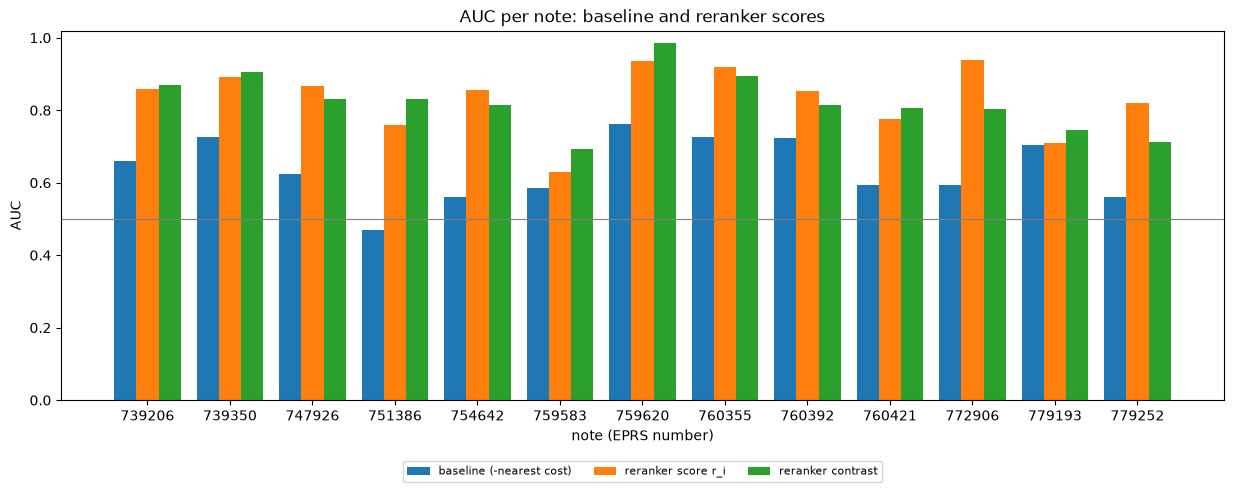

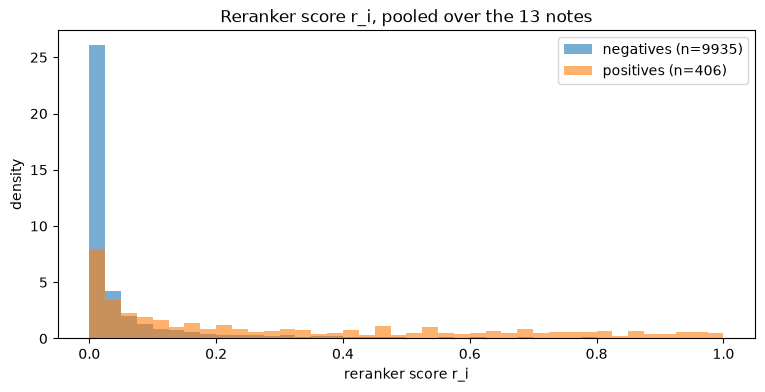

pooled r_i: positives median 0.1885, negatives median 0.0104

In [17]:
fig, ax = plt.subplots(figsize=(15, 4.8))
width = 0.27
for k, (name, text) in enumerate([("baseline", "baseline (-nearest cost)"), ("reranker", "reranker score r_i"), ("contrast", "reranker contrast")]):
    ax.bar(np.arange(13) + k * width, [AUC[name][t] for t in TARGET_IDS], width, label=text)
ax.set_xticks(np.arange(13) + width, [t[:6] for t in TARGET_IDS])
ax.axhline(0.5, color="grey", lw=0.8)
ax.set_xlabel("note (EPRS number)"); ax.set_ylabel("AUC"); ax.set_ylim(0.0, 1.02)
ax.set_title("AUC per note: baseline and reranker scores"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15), fontsize=8)
plt.show()

pos_r = np.concatenate([RERANK_R[t][LAB[t]["pos"]] for t in TARGET_IDS])
neg_r = np.concatenate([RERANK_R[t][LAB[t]["neg"]] for t in TARGET_IDS])
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 1, 41)
ax.hist(neg_r, bins=bins, alpha=0.6, density=True, label=f"negatives (n={len(neg_r)})")
ax.hist(pos_r, bins=bins, alpha=0.6, density=True, label=f"positives (n={len(pos_r)})")
ax.set_xlabel("reranker score r_i"); ax.set_ylabel("density"); ax.set_title("Reranker score r_i, pooled over the 13 notes"); ax.legend()
plt.show()
console.print(f"pooled r_i: positives median {np.median(pos_r):.4f}, negatives median {np.median(neg_r):.4f}")

## Metrics JSON

Every measured number, the gate value, the bar clauses as value and boolean, and the verdict by bar are written to `reports/E19-real-document-reranker-metrics.json`.

In [18]:
metrics = {
    "batch": "E19", "notebook": "A", "hypothesis": "E19-H95",
    "written_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "environment": {"docdistance": docdistance.__version__, "python": platform.python_version(), "numpy": np.__version__, "POT": ot.__version__,
                    "encoder_backend": dd.backend, "reranker_class_in_last_run": RERANKER_CLASS, "reranker_defaults": "load_reranker()",
                    "reader": "default (auto by extension)", "DIFF_CHANGED_COST": DIFF_CHANGED_COST},
    "fixture_sha256": fixture_sha, "fixture_sha256_equals_registration": HASH_EQUAL,
    "harness_check": {"fixture_hash_equal": HASH_EQUAL, "label_count_assertion_passed": LABEL_ASSERTION_PASSED, "largest_difference": 0.0},
    "statement_counts": {"report": N_REPORT, "notes": {n: len(NOTE_TEXTS[n]) for n in NOTE_IDS}, "units": len(UNITS)},
    "label_counts": {n: {"positives": int(l["pos"].sum()), "neutral": int(l["neutral"].sum()), "negatives": int(l["neg"].sum()),
                         "hard_negatives": None if l["hard"] is None else int(l["hard"].sum())} for n, l in LAB.items()},
    "auc_per_note": {n: {s: AUC[s][n] for s in NAMES} for n in TARGET_IDS},
    "auc_hard_negatives_per_note": {n: {s: AUC_HARD[s][n] for s in NAMES} for n in TARGET_IDS},
    "summary_13_notes": SUMMARY,
    "section_reading": {s: {n: SECTION[s][n] for n in NOTE_IDS} for s in NAMES},
    "balanced_accuracy": {"fixed_cutoff_nearest_cost": FIXED, "otsu_reranker": OTSU, "mean_fixed": FIXED_MEAN, "mean_otsu": OTSU_MEAN},
    "note_without_target": {"note": NT, **NT_READING, "reference_13_notes": NT_REFERENCE},
    "gates": {"E19-H95": {"baseline_mean_auc": BASE_MEAN, "threshold": BATCH_GATE_AUC, "killed": H95_KILLED, "reading": GATE_READING}},
    "clauses": {"E19-H95": {**CLAUSES, "bar_met": BAR_MET}},
    "verdict_by_bar": {"E19-H95": VERDICT},
    "reranker": {"grids_computed_last_run": N_COMPUTED, "grids_read_from_file_last_run": N_FROM_FILE, "grids_file": str(GRIDS_FILE.relative_to(ROOT)),
                 "seconds_per_note": GRID_SECONDS, "pairs_per_note": PAIRS, "seconds_per_1000_pairs": SECONDS_PER_1000,
                 "total_seconds": sum(GRID_SECONDS.values()), "total_pairs": sum(PAIRS.values())},
    "per_note_table": PER_NOTE,
    "wall_seconds_last_run": round(time.time() - T_START, 1),
}
METRICS_FILE.write_text(json.dumps(metrics, indent=1, default=float), encoding="utf-8")
console.print(f"written {METRICS_FILE.relative_to(ROOT)} ({METRICS_FILE.stat().st_size} bytes)")
console.print(metrics["verdict_by_bar"])

written reports/E19-real-document-reranker-metrics.json (349969 bytes)

{'E19-H95': 'Confirmed'}

## Conclusions

**Gate.** The baseline mean AUC over the 13 notes is 0.6374, below the batch gate of 0.95, so `E19-H95` goes on to its bar.

**E19-H95 - Confirmed by the registered bar.** The reranker score `r_i` has a mean AUC of 0.8321 against 0.6374 for the nearest cost. The mean difference is +0.1947 (bar: at least 0.03) and the difference is above 0 in 13 of 13 notes (bar: at least 10). The bootstrap 95% interval of the mean difference over notes is [+0.1440, +0.2434]. The prediction (gain of 0.05 or more, positive in at least 10 notes) is met with a wide margin.

**Reported without a bar.**

- Hard negatives (negatives of the chapter of the first target): reranker mean AUC 0.8187 against 0.6305 for the baseline, so the gain does not depend on easy negatives from other chapters
- Section reading: the best target unit is in the top 3 for 12 of 13 notes with the reranker against 5 of 13 with the baseline; the median rank of the best target unit is 1 against 6
- Contrast of `r_i` (minus its mean over the other 12 notes): mean AUC 0.8231, +0.1857 to the baseline, 13 of 13 notes above 0, 12 of 13 top-3 hits; it does not exceed `r_i` itself on this fixture
- Otsu split of `r_i`: mean balanced accuracy 0.6846 against 0.5835 for the fixed cutoff on the nearest cost; this carries no bar here
- Two notes gain little: 759583 (+0.0460, best target unit at rank 4) and 779193 (+0.0074, rank 3 for the reranker, rank 1 for the baseline); the 13 gains range from +0.0074 to +0.3449
- Note without a target (760391): the reranker scores are low (median 0.0031) and the Otsu split of `r_i` marks 3.3% of the report statements as a match, the fixed cutoff 2.3%, against means of 8.5% and 6.2% over the 13 notes with a target; its 3 best-ranked units are 2.1 (technological leadership), 5.2 (implementation of the regulatory environment) and 2.1.2 (Digital Single Market), so the section reading returns units for a note that has no target section
- Cost: 444,149 pairs took 11,907 s of reranker time in this run, 26.8 s per 1000 pairs, on a CPU shared with other jobs, so the time is not a benchmark; the registered estimate was about 2 hours. The 14 grids were computed in the first execution and are read from `data/interim/E19/reranker-grids.npz` in a later one

**What the fixture cannot show.** One report, 13 notes, one annotator, labels at section level: a statement outside a target section can be relevant to a note, and such statements count as negatives. The notes come from one institution and were written about legislative files, not for this report. The sign test over 13 notes and the interval over notes describe these 13 notes only. Neutral statements, and the removal of units under 5 statements, change the pool the metrics read. The result does not tell whether the reranker also helps on a report of one broad topic beyond what `E18-H87` showed, nor on documents of another language or domain.